# Extract geographic rasters from a deformation surface

Install `deform2tsunami` in the notebook's Python environment. Put a rupture's **surface.h5** beside this notebook or set its path below. This example exports 30 arcsecond GeoTIFFs over offshore Oregon. For a different source, change the bounds or use `None` for its full extent.

In [1]:
import os
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import rasterio
from rasterio.plot import plotting_extent
from deform2tsunami import export_raster

source = Path(os.environ.get("DEFORM2TSUNAMI_EXAMPLE", "surface.h5")).expanduser()
bounds = (-125.8, 44.5, -124.1, 45.6)  # west, south, east, north in degrees
arcsec = 30
out = Path("rasters")
out.mkdir(exist_ok=True)
with h5py.File(source, "r") as h:
    print("Input:", h.attrs.get("scenario", source.name))
    has_eta0 = "tsunami/eta0" in h
    print("Archived initial water surface present:", has_eta0)

Input: DOGAMI-Aexp-T100-S-Sym-L-U
Archived initial water surface present: False


## Write the GeoTIFFs

Vertical displacement and slope-corrected bed change come from the original deformation. If the file includes an archived initial water surface, export it too. The separate recomputation shows how to obtain a water surface directly from deformation. Rerunning this cell replaces the named example outputs in `rasters/`.

In [2]:
fields = ["vertical", "bed-change"]
if has_eta0:
    fields.append("eta0")
fields.append("eta0-recomputed")

paths = {}
for field in fields:
    paths[field] = export_raster(source, out / f"{field}.tif", field,
                                 bounds=bounds, arcsec=arcsec, overwrite=True)

for field, path in paths.items():
    with rasterio.open(path) as ds:
        grid = ds.read(1, masked=True)
        print(f"{path}  |  {ds.crs}  |  {ds.width} × {ds.height}  |  "
              f"{grid.min():.2f} to {grid.max():.2f} m")

rasters/vertical.tif  |  EPSG:4326  |  204 × 132  |  -2.03 to 9.28 m
rasters/bed-change.tif  |  EPSG:4326  |  204 × 132  |  -2.41 to 10.87 m
rasters/eta0-recomputed.tif  |  EPSG:4326  |  204 × 132  |  -2.09 to 7.43 m


## Read and compare the rasters

All panels share a color scale. Positive values indicate uplift or water above the initial still-water level. Blank pixels have no supported value for that field.

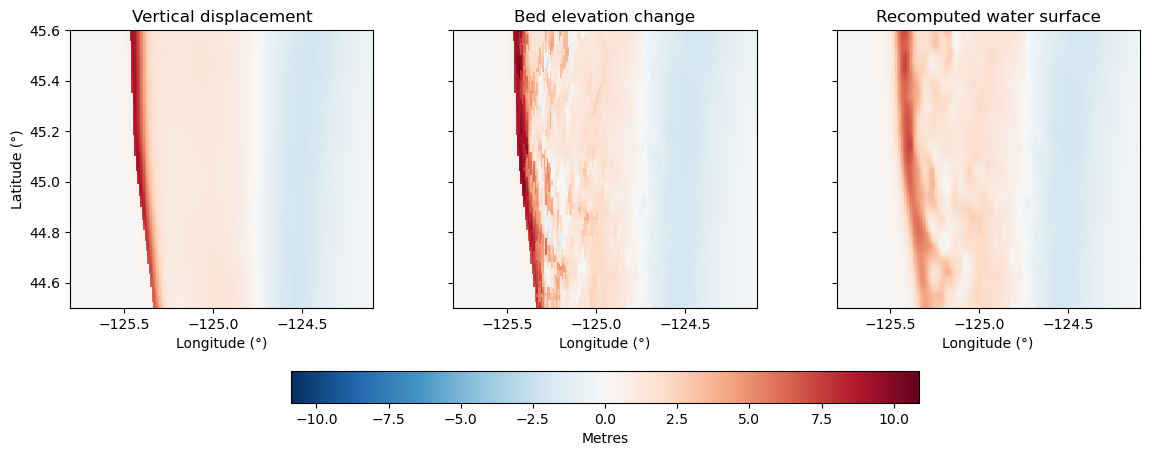

In [3]:
fig, axes = plt.subplots(1, len(paths), figsize=(4 * len(paths), 4.4),
                         sharex=True, sharey=True, constrained_layout=True)
titles = {"vertical": "Vertical displacement", "bed-change": "Bed elevation change",
          "eta0": "Archived water surface", "eta0-recomputed": "Recomputed water surface"}
limit = 0
images = []
for ax, (field, path) in zip(axes, paths.items()):
    with rasterio.open(path) as ds:
        grid = ds.read(1, masked=True)
        images.append(ax.imshow(grid, extent=plotting_extent(ds), cmap="RdBu_r",
                                interpolation="nearest", origin="upper"))
        if grid.count():
            limit = max(limit, float(np.abs(grid).max()))
        latitude = (ds.bounds.bottom + ds.bounds.top) / 2
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.set_aspect(1 / np.cos(np.deg2rad(latitude)))
    ax.set(title=titles[field], xlabel="Longitude (°)")
for image in images:
    image.set_clim(-max(limit, 0.01), max(limit, 0.01))
axes[0].set_ylabel("Latitude (°)")
fig.colorbar(images[0], ax=list(axes), orientation="horizontal", shrink=.55, label="Metres")
plt.show()